In [46]:
# Cargar df_podado y configurar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_podado = pd.read_csv('../data/df_podado.csv')
# Convertir las columnas de fecha a datetime para mantener el comportamiento
for col in ['date', 'r_dob', 'b_dob']:
    if col in df_podado.columns:
        df_podado[col] = pd.to_datetime(df_podado[col], errors='coerce')
if 'date' in df_podado.columns:
    df_podado['year'] = df_podado['date'].dt.year

print("df_podado cargado exitosamente.")

df_podado cargado exitosamente.


## Perfil físico y biográfico

Aquí se comparan altura, peso, alcance, edad y postura. La meta es ver si el tamaño y la edad ya separan estilos o resultados.

In [47]:
# Partimos de eda_male (1 fila = 1 pelea)
# Primero, nos quedamos solo con las peleas que tienen un ganador claro (donde winner_id no es nulo)
eda_wl = df_podado.dropna(subset=['winner_id']).copy()

# Listamos dinámicamente las columnas que pertenecen a cada esquina
r_cols = [c for c in eda_wl.columns if c.startswith('r_')]
b_cols = [c for c in eda_wl.columns if c.startswith('b_')]

# Separamos el dataset en peleas ganadas por el Rojo y ganadas por el Azul
red_wins = eda_wl[eda_wl['winner_id'] == eda_wl['r_id']].copy()
blue_wins = eda_wl[eda_wl['winner_id'] == eda_wl['b_id']].copy()

# Para las peleas que ganó el Rojo: r_ pasa a ser w_ (winner) y b_ pasa a ser l_ (loser)
rename_red = {c: 'w_' + c[2:] for c in r_cols}
rename_red.update({c: 'l_' + c[2:] for c in b_cols})
red_wins = red_wins.rename(columns=rename_red)

# Para las peleas que ganó el Azul: b_ pasa a ser w_ (winner) y r_ pasa a ser l_ (loser)
rename_blue = {c: 'w_' + c[2:] for c in b_cols}
rename_blue.update({c: 'l_' + c[2:] for c in r_cols})
blue_wins = blue_wins.rename(columns=rename_blue)

# Concatenamos ambos subsets para obtener el nuevo dataset orientado por Winner/Loser
eda_wl = pd.concat([red_wins, blue_wins], ignore_index=True)

# (Opcional) Si tenías columnas calculadas basadas en la esquina (ej. la diferencia de edad),
# la eliminamos o recalculamos basándonos en Winner - Loser
if 'age_diff_rb' in eda_wl.columns:
    eda_wl = eda_wl.drop(columns=['age_diff_rb'])
if 'w_age' in eda_wl.columns and 'l_age' in eda_wl.columns:
    eda_wl['age_diff_wl'] = eda_wl['w_age'] - eda_wl['l_age']

print(f"Dataset original (eda_male): {df_podado.shape}")
print(f"Nuevo dataset orientado a Ganador/Perdedor (eda_wl): {eda_wl.shape}")

# Verificamos rápidamente algunas columnas
w_cols = [c for c in eda_wl.columns if c.startswith('w_')]
print(f"\nSe generaron {len(w_cols)} columnas para el ganador. Ejemplo: {w_cols[:5]}")


Dataset original (eda_male): (6206, 126)
Nuevo dataset orientado a Ganador/Perdedor (eda_wl): (6082, 126)

Se generaron 55 columnas para el ganador. Ejemplo: ['w_name', 'w_id', 'w_kd', 'w_sig_str_landed', 'w_sig_str_atmpted']


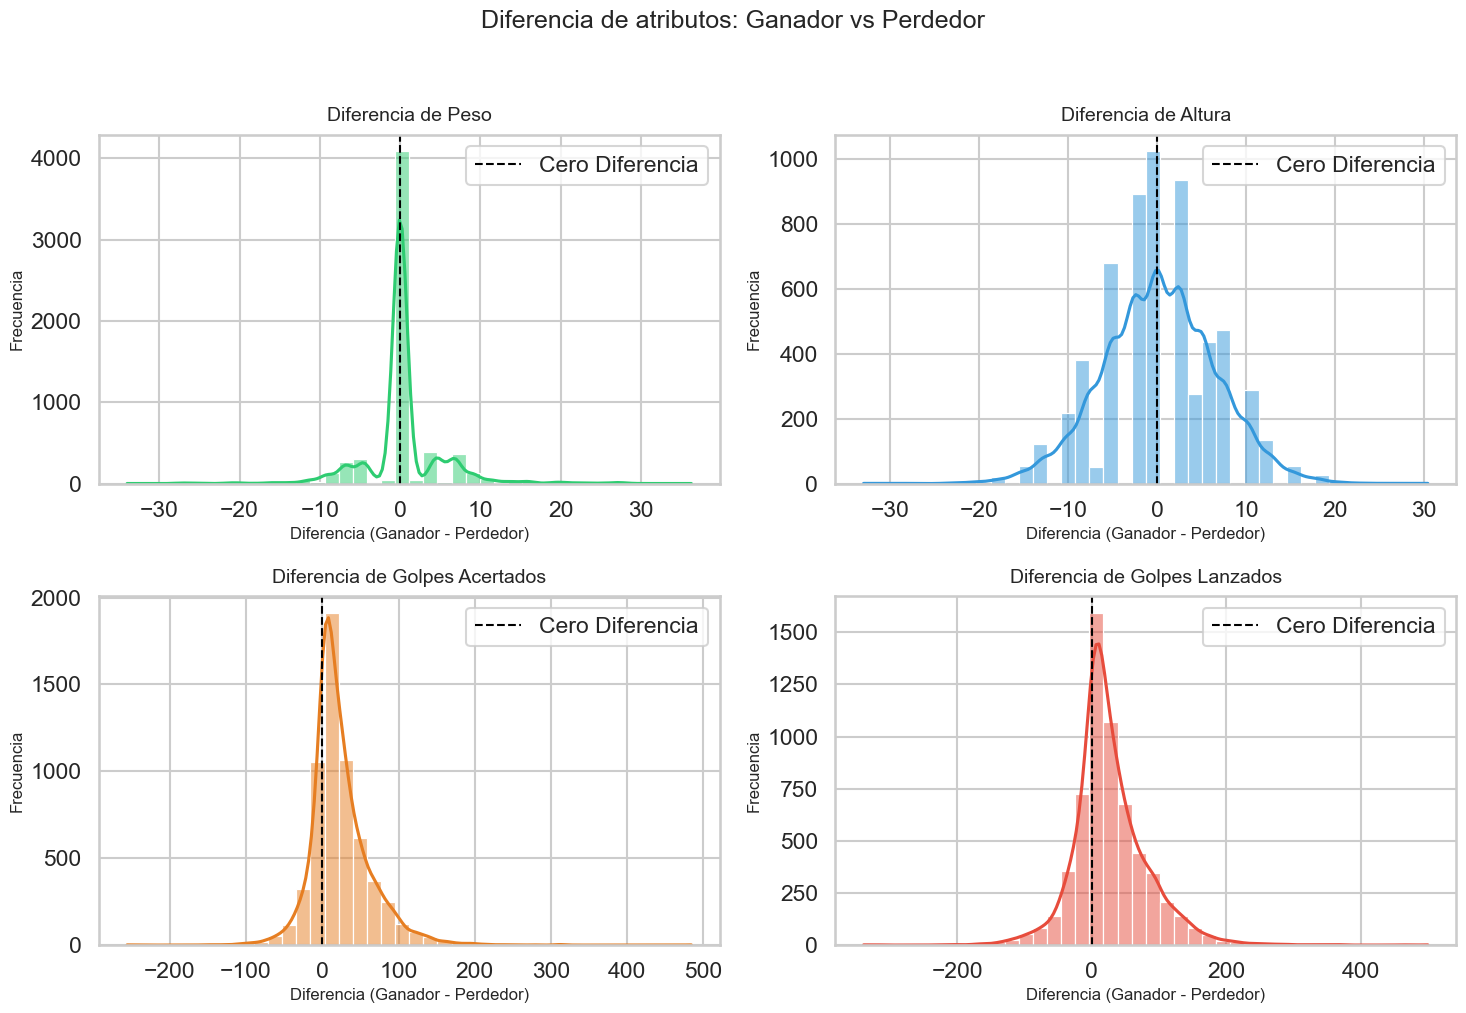

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculamos las diferencias (Ganador - Perdedor)
eda_wl['weight_diff'] = eda_wl['w_weight'] - eda_wl['l_weight']
eda_wl['height_diff'] = eda_wl['w_height'] - eda_wl['l_height']

# Usamos 'total_str' (Golpes totales). Si prefieres golpes significativos, 
# puedes cambiar 'total_str' por 'sig_str' en estas dos líneas.
eda_wl['str_landed_diff'] = eda_wl['w_total_str_landed'] - eda_wl['l_total_str_landed']
eda_wl['str_atmpted_diff'] = eda_wl['w_total_str_atmpted'] - eda_wl['l_total_str_atmpted']

# 2. Configuramos la figura con 4 gráficos (2 filas x 2 columnas)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Diferencia de atributos: Ganador vs Perdedor', fontsize=18, y=1.02)

# Lista de configuración para los gráficos: (Columna, Título, Eje, Color)
graficos = [
    ('weight_diff', 'Diferencia de Peso', axes[0, 0], '#2ecc71'),
    ('height_diff', 'Diferencia de Altura', axes[0, 1], '#3498db'),
    ('str_landed_diff', 'Diferencia de Golpes Acertados', axes[1, 0], '#e67e22'),
    ('str_atmpted_diff', 'Diferencia de Golpes Lanzados', axes[1, 1], '#e74c3c')
]

# 3. Iteramos y generamos cada gráfico
for col, title, ax, color in graficos:
    # Graficamos el histograma con su curva de densidad (KDE)
    sns.histplot(data=eda_wl, x=col, kde=True, ax=ax, color=color, bins=40)
    
    # Línea vertical punteada en 0 (Referencia de "Igualdad")
    # Valores > 0 significan que el Ganador tuvo más. Valores < 0 significan que el Perdedor tuvo más.
    ax.axvline(0, color='black', linestyle='--', linewidth=1.5, label='Cero Diferencia')
    
    ax.set_title(title, fontsize=14, pad=10)
    ax.set_xlabel('Diferencia (Ganador - Perdedor)', fontsize=12)
    ax.set_ylabel('Frecuencia', fontsize=12)
    ax.legend()

plt.tight_layout()
plt.show()


C:\Users\ml328\AppData\Local\Temp\ipykernel_13836\1691240269.py:56: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


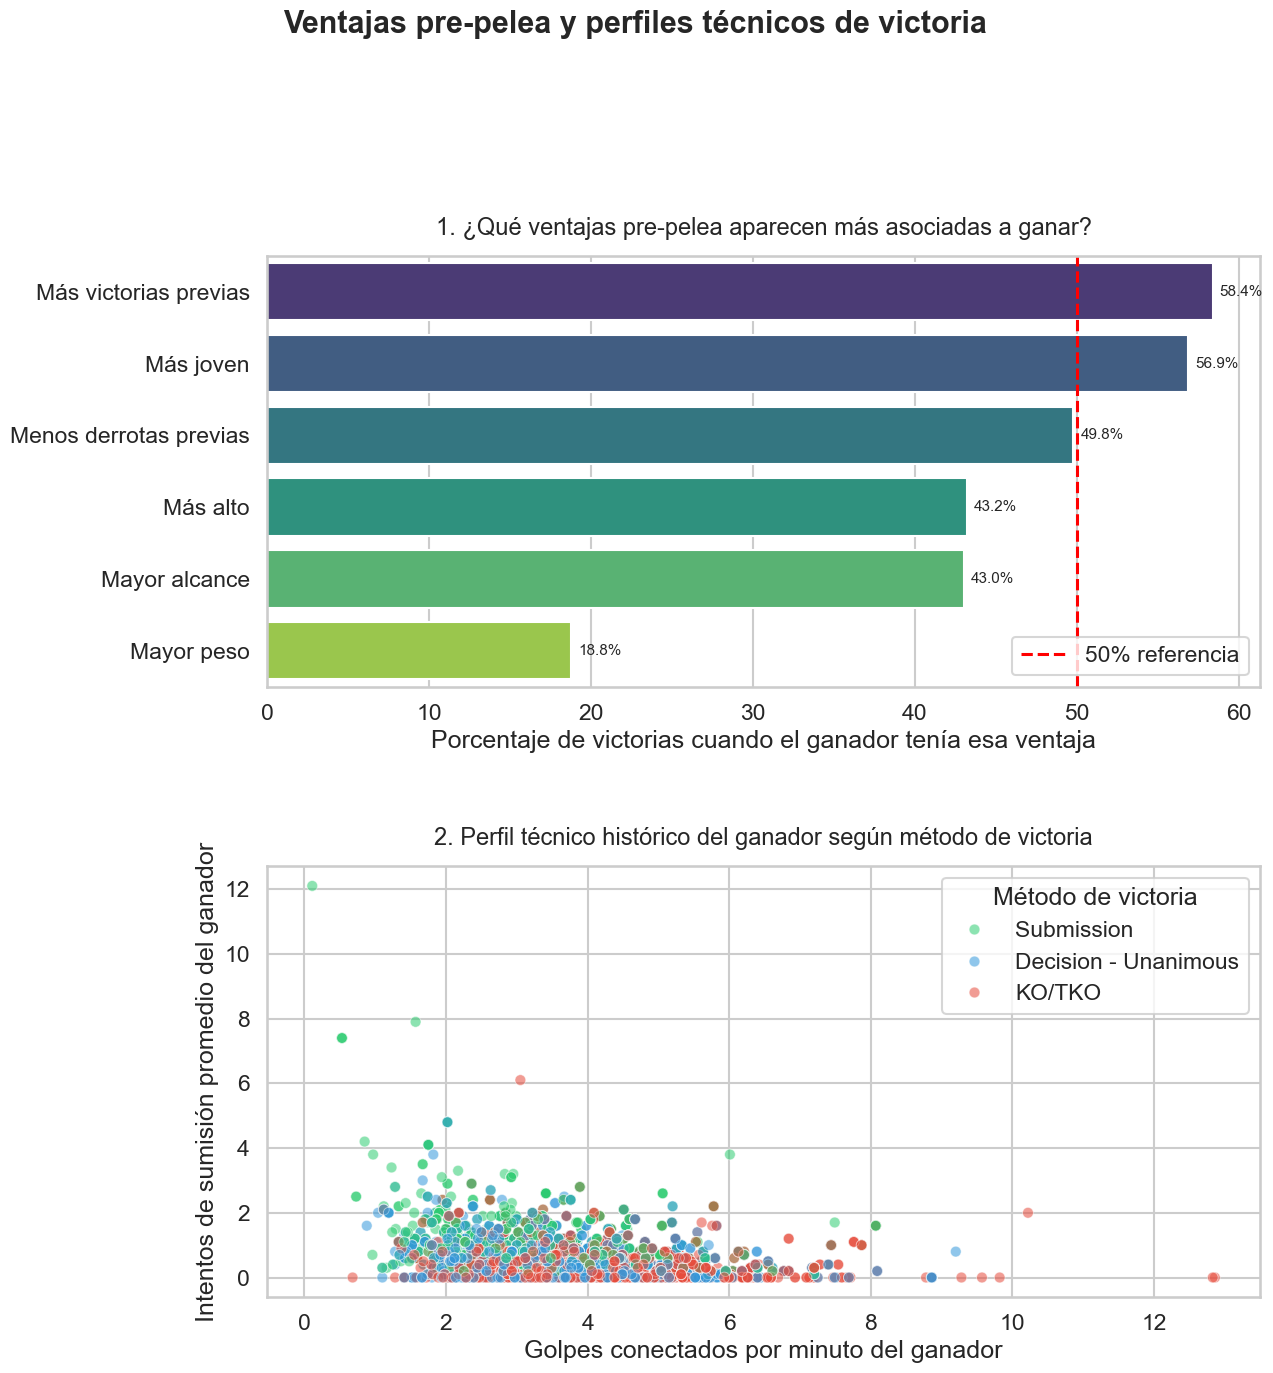

In [49]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------
# 0. Preparación
# -----------------------------

eda_wl_clean = eda_wl.copy()

eda_wl_clean['date'] = pd.to_datetime(eda_wl_clean['date'], errors='coerce')
eda_wl_clean['w_dob'] = pd.to_datetime(eda_wl_clean['w_dob'], errors='coerce')
eda_wl_clean['l_dob'] = pd.to_datetime(eda_wl_clean['l_dob'], errors='coerce')

eda_wl_clean['w_age'] = (eda_wl_clean['date'] - eda_wl_clean['w_dob']).dt.days / 365.25
eda_wl_clean['l_age'] = (eda_wl_clean['date'] - eda_wl_clean['l_dob']).dt.days / 365.25

# Filtramos métodos principales
main_methods = eda_wl_clean[
    eda_wl_clean['method'].isin(['KO/TKO', 'Submission', 'Decision - Unanimous'])
].copy()

# -----------------------------
# 1. Grilla
# -----------------------------

sns.set_theme(style="whitegrid", context="talk")

fig, axes = plt.subplots(2, 1, figsize=(14, 14))
fig.suptitle(
    "Ventajas pre-pelea y perfiles técnicos de victoria",
    fontsize=22,
    fontweight="bold",
    y=1.02
)

# -----------------------------
# GRÁFICO 1: Ventajas pre-pelea
# -----------------------------

adv_stats = {
    'Más joven': (eda_wl_clean['w_age'] < eda_wl_clean['l_age']).mean() * 100,
    'Más alto': (eda_wl_clean['w_height'] > eda_wl_clean['l_height']).mean() * 100,
    'Mayor alcance': (eda_wl_clean['w_reach'] > eda_wl_clean['l_reach']).mean() * 100,
    'Mayor peso': (eda_wl_clean['w_weight'] > eda_wl_clean['l_weight']).mean() * 100,
    'Más victorias previas': (eda_wl_clean['w_wins'] > eda_wl_clean['l_wins']).mean() * 100,
    'Menos derrotas previas': (eda_wl_clean['w_losses'] < eda_wl_clean['l_losses']).mean() * 100,
}

adv_df = (
    pd.DataFrame(list(adv_stats.items()), columns=['Ventaja pre-pelea', 'Porcentaje de victorias'])
    .dropna()
    .sort_values('Porcentaje de victorias', ascending=False)
)

sns.barplot(
    data=adv_df,
    x='Porcentaje de victorias',
    y='Ventaja pre-pelea',
    ax=axes[0],
    palette="viridis"
)

axes[0].axvline(
    50,
    color='red',
    linestyle='--',
    linewidth=2.2,
    label='50% referencia'
)

axes[0].set_title(
    "1. ¿Qué ventajas pre-pelea aparecen más asociadas a ganar?",
    fontsize=17,
    pad=15
)
axes[0].set_xlabel("Porcentaje de victorias cuando el ganador tenía esa ventaja")
axes[0].set_ylabel("")
axes[0].legend(loc="lower right")

# Agregar valores al final de las barras
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f%%", padding=5, fontsize=11)

# -----------------------------
# GRÁFICO 2: Perfil técnico histórico según método
# -----------------------------

sns.scatterplot(
    data=main_methods,
    x='w_splm',
    y='w_sub_avg',
    hue='method',
    alpha=0.55,
    s=60,
    ax=axes[1],
    palette={
        'KO/TKO': '#e74c3c',
        'Submission': '#2ecc71',
        'Decision - Unanimous': '#3498db'
    }
)

axes[1].set_title(
    "2. Perfil técnico histórico del ganador según método de victoria",
    fontsize=17,
    pad=15
)
axes[1].set_xlabel("Golpes conectados por minuto del ganador")
axes[1].set_ylabel("Intentos de sumisión promedio del ganador")
axes[1].legend(title='Método de victoria')

plt.tight_layout(pad=3.0)
plt.show()

## Estilo y desempeño

Estas celdas miran producción ofensiva, defensa, derribos y sumisiones. Acá se ve el perfil de pelea, no solo el resultado.

## Ventaja relativa y resultado

Aquí construimos diferencias rojo menos azul en variables clave para ver qué señales separan victorias, derrotas y empates.

## Evolución Temporal de la UFC

In [50]:
df_evo = df_podado.copy()

df_evo['date'] = pd.to_datetime(df_evo['date'], errors='coerce')
df_evo = df_evo.dropna(subset=['date'])

df_evo['year'] = df_evo['date'].dt.year
df_evo['duration_min'] = df_evo['match_time_sec'] / 60

# Agrupamos métodos para evitar demasiadas categorías
def simplify_method(method):
    if pd.isna(method):
        return 'Other'
    method = str(method)
    if 'KO/TKO' in method or 'TKO' in method:
        return 'KO/TKO'
    elif 'Submission' in method:
        return 'Submission'
    elif 'Decision' in method:
        return 'Decision'
    else:
        return 'Other'

df_evo['method_group'] = df_evo['method'].apply(simplify_method)

# Métricas técnicas promedio entre Red y Blue
df_evo['avg_splm'] = df_evo[['r_splm', 'b_splm']].mean(axis=1)
df_evo['avg_sapm'] = df_evo[['r_sapm', 'b_sapm']].mean(axis=1)
df_evo['avg_str_acc'] = df_evo[['r_str_acc', 'b_str_acc']].mean(axis=1)
df_evo['avg_str_def'] = df_evo[['r_str_def', 'b_str_def']].mean(axis=1)
df_evo['avg_td_avg'] = df_evo[['r_td_avg', 'b_td_avg']].mean(axis=1)
df_evo['avg_sub_avg'] = df_evo[['r_sub_avg', 'b_sub_avg']].mean(axis=1)

# Para evitar ruido de años con muy pocas peleas
fights_per_year = df_evo.groupby('year').size()
valid_years = fights_per_year[fights_per_year >= 20].index
df_evo = df_evo[df_evo['year'].isin(valid_years)]

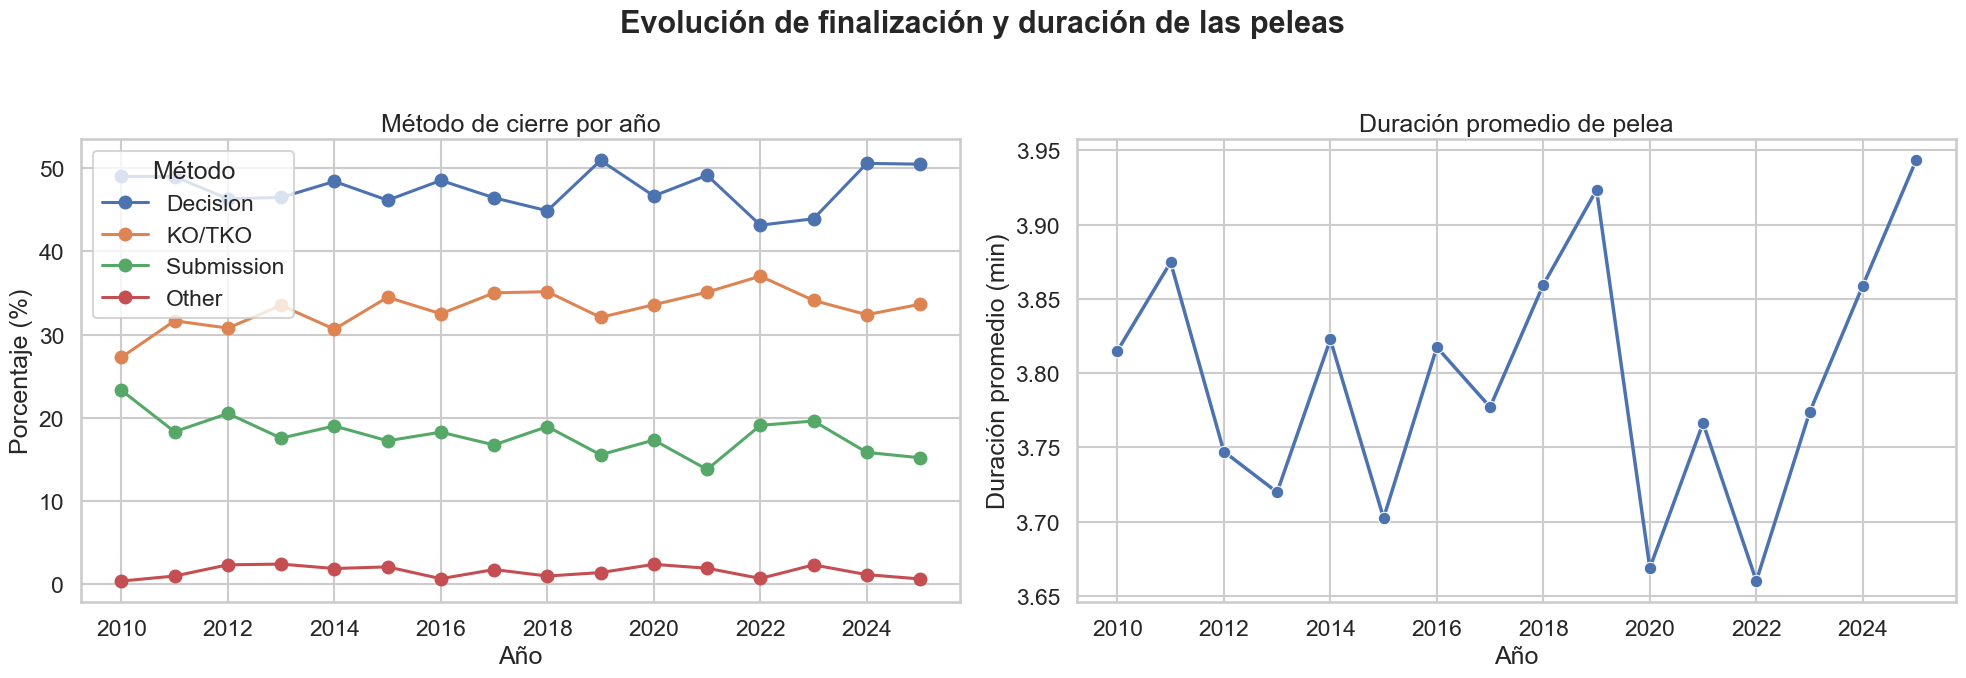

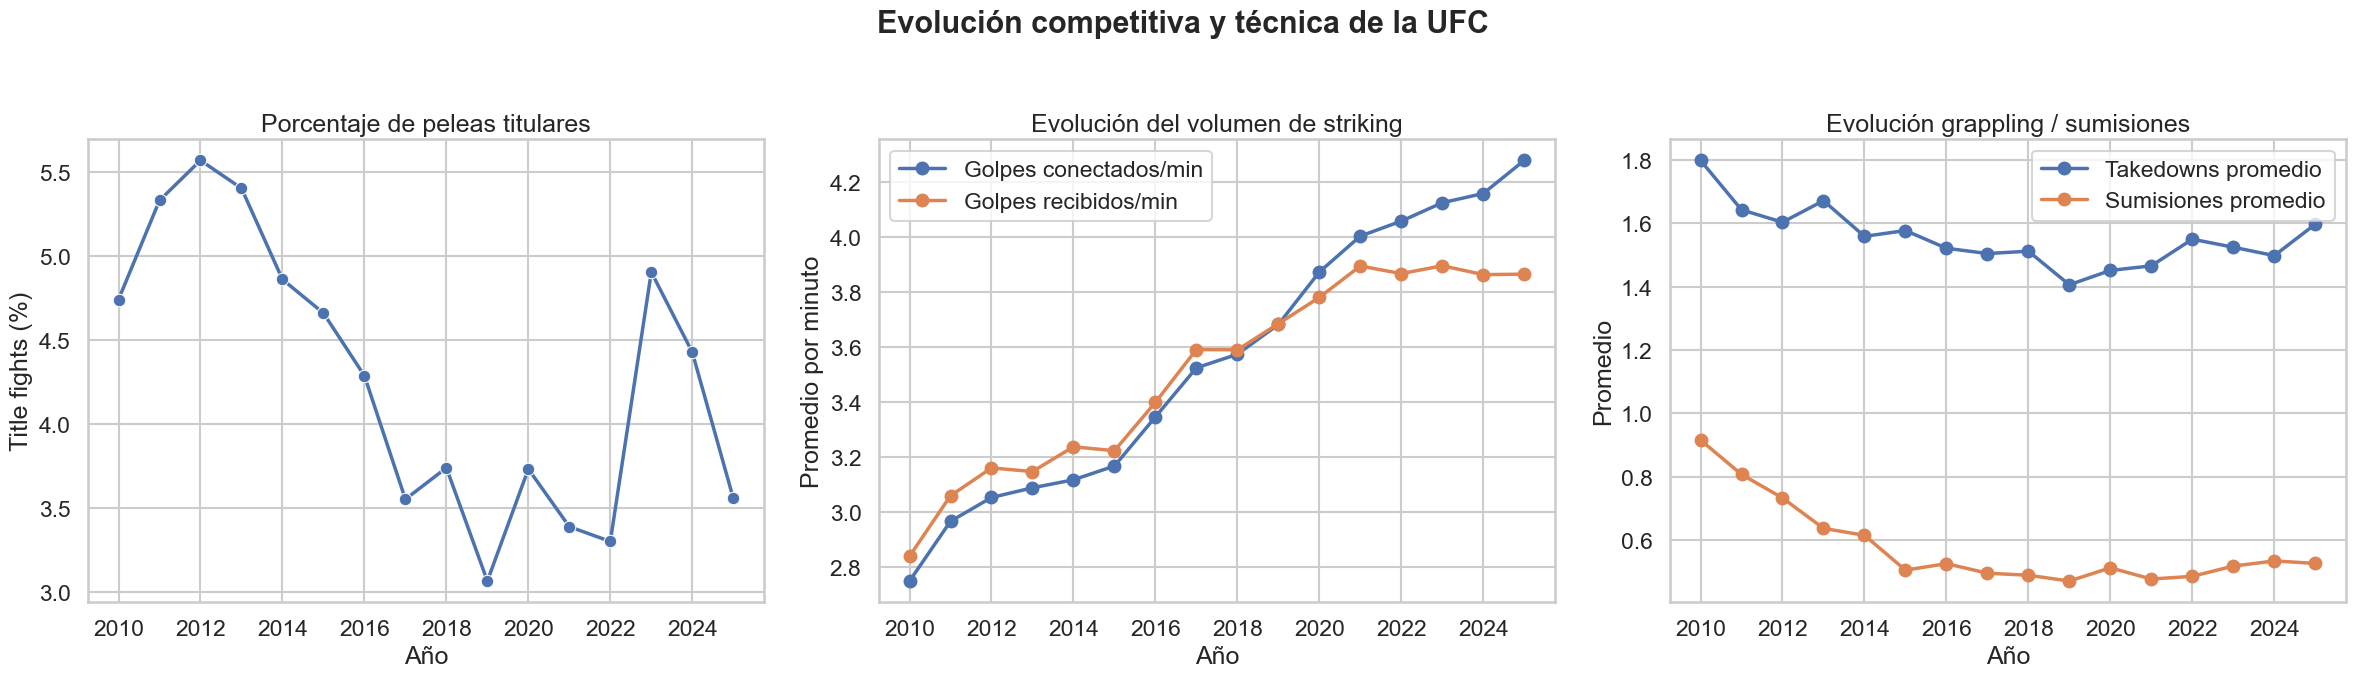

In [51]:
sns.set_theme(style="whitegrid", context="talk")

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
fig.suptitle("Evolución de finalización y duración de las peleas", fontsize=22, fontweight="bold")

# -----------------------------
# Métodos de cierre
# -----------------------------

method_year = (
    df_evo
    .groupby(['year', 'method_group'])
    .size()
    .reset_index(name='count')
)

method_pivot = method_year.pivot(
    index='year',
    columns='method_group',
    values='count'
).fillna(0)

method_pct = method_pivot.div(method_pivot.sum(axis=1), axis=0) * 100

method_cols = [col for col in ['Decision', 'KO/TKO', 'Submission', 'Other'] if col in method_pct.columns]

for col in method_cols:
    axes[0].plot(
        method_pct.index,
        method_pct[col],
        marker='o',
        linewidth=2.2,
        label=col
    )

axes[0].set_title("Método de cierre por año")
axes[0].set_xlabel("Año")
axes[0].set_ylabel("Porcentaje (%)")
axes[0].legend(title="Método")

# -----------------------------
# Duración promedio
# -----------------------------

duration_year = (
    df_evo
    .groupby('year')['duration_min']
    .mean()
    .reset_index()
)

sns.lineplot(
    data=duration_year,
    x='year',
    y='duration_min',
    marker='o',
    linewidth=2.5,
    ax=axes[1]
)

axes[1].set_title("Duración promedio de pelea")
axes[1].set_xlabel("Año")
axes[1].set_ylabel("Duración promedio (min)")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("../figures/Evolucion_Metodos_Duracion.png", dpi=300, bbox_inches='tight')
plt.show()
sns.set_theme(style="whitegrid", context="talk")

fig, axes = plt.subplots(1, 3, figsize=(24, 7))
fig.suptitle("Evolución competitiva y técnica de la UFC", fontsize=22, fontweight="bold")

# -----------------------------
# Title fights
# -----------------------------

title_year = (
    df_evo
    .groupby('year')['title_fight']
    .mean()
    .mul(100)
    .reset_index(name='title_fight_pct')
)

sns.lineplot(
    data=title_year,
    x='year',
    y='title_fight_pct',
    marker='o',
    linewidth=2.5,
    ax=axes[0]
)

axes[0].set_title("Porcentaje de peleas titulares")
axes[0].set_xlabel("Año")
axes[0].set_ylabel("Title fights (%)")

# -----------------------------
# Striking
# -----------------------------

tech_striking_year = (
    df_evo
    .groupby('year')[['avg_splm', 'avg_sapm']]
    .mean()
    .reset_index()
)

axes[1].plot(
    tech_striking_year['year'],
    tech_striking_year['avg_splm'],
    marker='o',
    linewidth=2.5,
    label='Golpes conectados/min'
)

axes[1].plot(
    tech_striking_year['year'],
    tech_striking_year['avg_sapm'],
    marker='o',
    linewidth=2.5,
    label='Golpes recibidos/min'
)

axes[1].set_title("Evolución del volumen de striking")
axes[1].set_xlabel("Año")
axes[1].set_ylabel("Promedio por minuto")
axes[1].legend()

# -----------------------------
# Grappling
# -----------------------------

tech_grappling_year = (
    df_evo
    .groupby('year')[['avg_td_avg', 'avg_sub_avg']]
    .mean()
    .reset_index()
)

axes[2].plot(
    tech_grappling_year['year'],
    tech_grappling_year['avg_td_avg'],
    marker='o',
    linewidth=2.5,
    label='Takedowns promedio'
)

axes[2].plot(
    tech_grappling_year['year'],
    tech_grappling_year['avg_sub_avg'],
    marker='o',
    linewidth=2.5,
    label='Sumisiones promedio'
)

axes[2].set_title("Evolución grappling / sumisiones")
axes[2].set_xlabel("Año")
axes[2].set_ylabel("Promedio")
axes[2].legend()

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("../figures/Evolucion_Tecnica.png", dpi=300, bbox_inches='tight')
plt.show()


Se puede observar que la UFC no solo aumentó su volumen de peleas con el tiempo, sino que también parece haberse vuelto un deporte más estable, profesionalizado y estratégico. A medida que avanzan los años, se observa una mayor acumulación de peleas por temporada, una tendencia a combates más largos y una mayor presencia relativa de decisiones frente a finalizaciones tempranas. Esto sugiere que los peleadores modernos llegan mejor preparados, con defensas más desarrolladas y con una capacidad superior para neutralizar amenazas de KO o sumisión.

## Matriz de Correlación Técnica

In [52]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------
# 1. Crear dataset en formato long
# -----------------------------

red_cols = {
    'r_splm': 'splm',
    'r_str_acc': 'str_acc',
    'r_sapm': 'sapm',
    'r_str_def': 'str_def',
    'r_td_avg': 'td_avg',
    'r_td_avg_acc': 'td_acc',
    'r_td_def': 'td_def',
    'r_sub_avg': 'sub_avg'
}

blue_cols = {
    'b_splm': 'splm',
    'b_str_acc': 'str_acc',
    'b_sapm': 'sapm',
    'b_str_def': 'str_def',
    'b_td_avg': 'td_avg',
    'b_td_avg_acc': 'td_acc',
    'b_td_def': 'td_def',
    'b_sub_avg': 'sub_avg'
}

red_df = df_podado[list(red_cols.keys())].rename(columns=red_cols)
red_df['corner'] = 'Red'

blue_df = df_podado[list(blue_cols.keys())].rename(columns=blue_cols)
blue_df['corner'] = 'Blue'

fighters_long = pd.concat([red_df, blue_df], ignore_index=True)

# Limpiar valores faltantes
fighters_long = fighters_long.dropna()

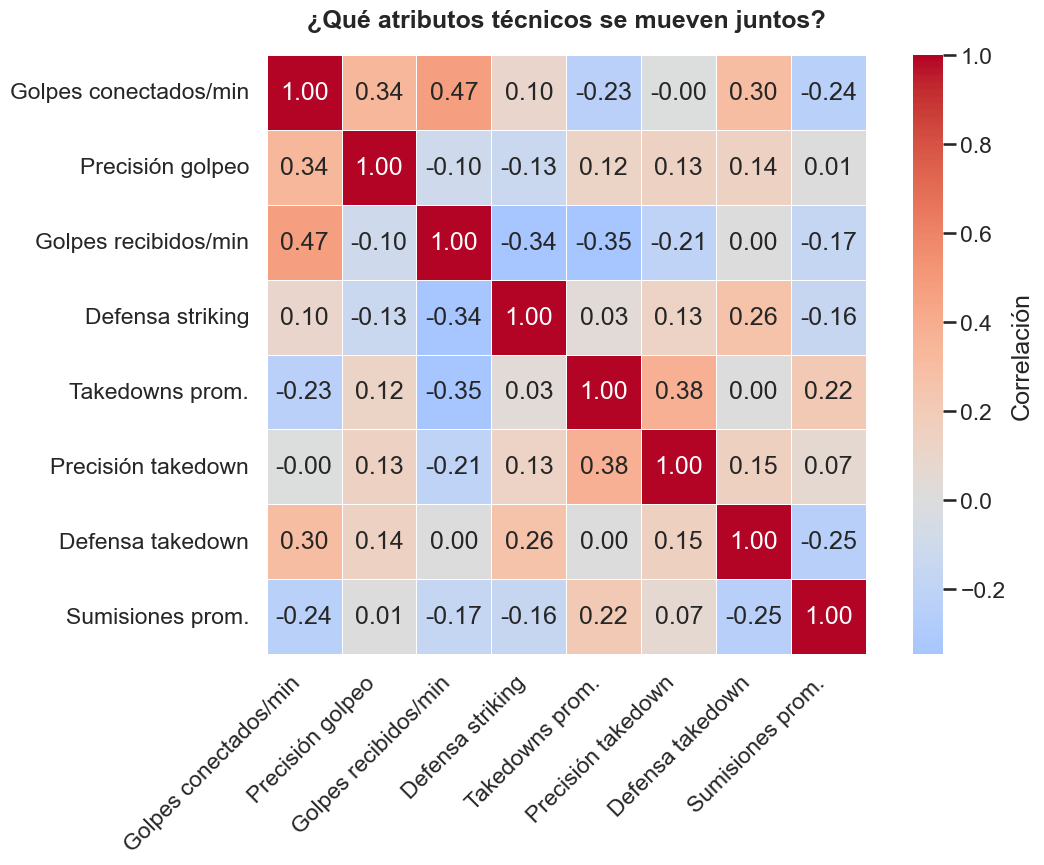

In [53]:
# -----------------------------
# 2. Matriz de correlación
# -----------------------------

technical_cols = [
    'splm',       # golpes conectados por minuto
    'str_acc',    # precisión de golpeo
    'sapm',       # golpes absorbidos por minuto
    'str_def',    # defensa de golpeo
    'td_avg',     # takedowns promedio
    'td_acc',     # precisión de takedown
    'td_def',     # defensa de takedown
    'sub_avg'     # intentos de sumisión promedio
]

corr_matrix = fighters_long[technical_cols].corr()

labels_es = {
    'splm': 'Golpes conectados/min',
    'str_acc': 'Precisión golpeo',
    'sapm': 'Golpes recibidos/min',
    'str_def': 'Defensa striking',
    'td_avg': 'Takedowns prom.',
    'td_acc': 'Precisión takedown',
    'td_def': 'Defensa takedown',
    'sub_avg': 'Sumisiones prom.'
}

corr_matrix_es = corr_matrix.rename(index=labels_es, columns=labels_es)

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix_es,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Correlación"}
)

plt.title("¿Qué atributos técnicos se mueven juntos?", fontsize=18, fontweight="bold", pad=20)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Esta matriz se interpreta de la siguiente manera: La correlación va de -1 a 1. Si en una unión el valor está cerca de 1, entonces suben juntos los atributos. Cerca de -1, uno sube cuando el otro baja. Cerca de 0	no hay relación lineal clara. 
Esto nos permite observar qué dimensiones técnicas tienden a moverse juntas dentro del dataset. En particular, permite distinguir si los perfiles ofensivos de striking se asocian con mayor exposición defensiva, si las métricas de grappling aparecen agrupadas entre sí y si las defensas técnicas —striking defense y takedown defense— se comportan como dimensiones independientes. Esta visualización no prueba causalidad, pero permite detectar patrones estructurales útiles para análisis posteriores de estilos de pelea y predicción de resultados.

In [54]:
# Guardar eda_wl_clean para el siguiente notebook
eda_wl_clean.to_csv('../data/eda_wl_clean.csv', index=False)
print("eda_wl_clean guardado en data/eda_wl_clean.csv exitosamente.")

eda_wl_clean guardado en data/eda_wl_clean.csv exitosamente.


## Justificación de k=3 y clustering de más atributos
Se utilizará el método del codo y el puntaje de silueta para justificar la elección de $k=3$.

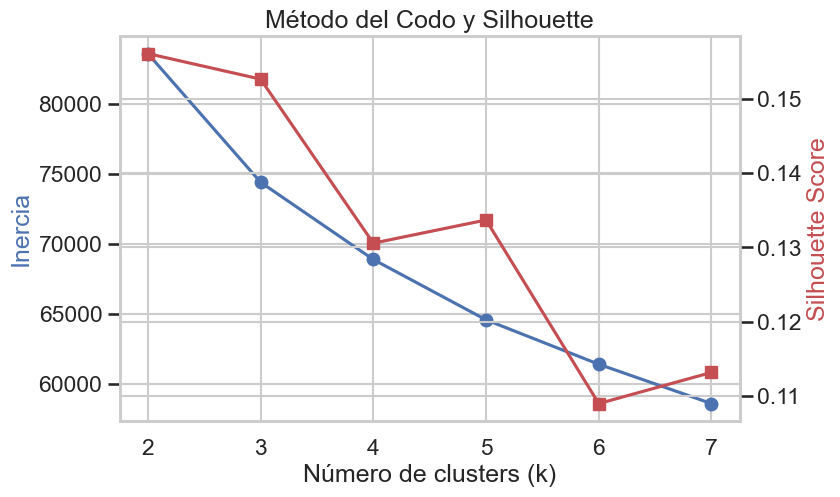

In [55]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import pandas as pd

cols_cluster = ['splm', 'str_acc', 'sapm', 'str_def', 'td_avg', 'td_acc', 'td_def', 'sub_avg']
X_cluster = fighters_long[cols_cluster].dropna()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

inertias = []
sil_scores = []
K_range = range(2, 8)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(X_scaled, kmeans.labels_))

fig, ax1 = plt.subplots(figsize=(8,5))
ax1.plot(K_range, inertias, marker='o', color='b', label='Inercia (Elbow)')
ax1.set_xlabel('Número de clusters (k)')
ax1.set_ylabel('Inercia', color='b')

ax2 = ax1.twinx()
ax2.plot(K_range, sil_scores, marker='s', color='r', label='Silhouette')
ax2.set_ylabel('Silhouette Score', color='r')
plt.title('Método del Codo y Silhouette')
plt.show()


El gráfico anterior permite justificar la elección de $k=3$. Procedemos a analizar los centroides para describir los clusters, atributo por atributo.

In [56]:
from IPython.display import display
kmeans3 = KMeans(n_clusters=3, random_state=42, n_init=10)
fighters_long['cluster'] = kmeans3.fit_predict(X_scaled)

# Inversión del escalado para interpretar los centroides en su escala original
centroids_original = scaler.inverse_transform(kmeans3.cluster_centers_)
df_centroids = pd.DataFrame(centroids_original, columns=cols_cluster)
df_centroids.index.name = 'Cluster'
display(df_centroids)




,splm,str_acc,sapm,str_def,td_avg,td_acc,td_def,sub_avg
Cluster,,,,,,,,
0,4.528489,45.994763,4.275519,53.963343,0.808310,31.339174,69.522256,0.280322
1,3.105843,45.864876,2.738397,57.139740,2.396204,47.009862,66.641838,0.568191
2,2.622145,41.920925,3.545860,48.875047,1.396378,28.524431,38.547184,1.085006


## Test Binomial: ¿El modelo supera significativamente el baseline?

El baseline del **58.4 %** es la *No-Information Rate* (NIR): predecir siempre la clase mayoritaria (Rojo) da 711/1217 ≈ 58.4 %. 
El Árbol de Decisión obtuvo **65.7 %** de accuracy. El test binomial de una proporción contrasta formalmente si ese 65.7 % es estadísticamente superior al 58.4 %:

- **H₀:** p = 0.584 (el modelo no supera el NIR)
- **H₁:** p > 0.584 (una cola superior)
- n = 1217, aciertos ≈ 0.657 × 1217 ≈ 800


In [57]:
from scipy.stats import binomtest
import numpy as np

# Parametros del modelo
n_total    = 1217          # tamano del conjunto de prueba
acc_modelo = 0.657         # accuracy del Arbol de Decision
nir        = 711 / 1217    # No-Information Rate (clase mayoritaria)

n_aciertos = round(acc_modelo * n_total)  # ~800

# Test binomial exacto (una cola: H1: p > NIR)
resultado = binomtest(n_aciertos, n_total, nir, alternative='greater')

print(f'NIR (baseline)   : {nir:.4f}  (711/{n_total})')
print(f'Accuracy modelo  : {acc_modelo:.4f}  ({n_aciertos}/{n_total} aciertos)')
print(f'p-value (H1>NIR) : {resultado.pvalue:.6f}')
print()
alpha = 0.05
if resultado.pvalue < alpha:
    print(f'Se rechaza H0 (p < {alpha}): el modelo supera significativamente el baseline.')
else:
    print(f'No se puede rechazar H0 (p >= {alpha}).')

# Aproximacion normal (z de una proporcion)
from scipy.stats import norm
p_hat = n_aciertos / n_total
se    = np.sqrt(nir * (1 - nir) / n_total)
z     = (p_hat - nir) / se
p_z   = 1 - norm.cdf(z)
print(f'\nAproximacion normal: z = {z:.4f}, p-value = {p_z:.6f}')


NIR (baseline)   : 0.5842  (711/1217)
Accuracy modelo  : 0.6570  (800/1217 aciertos)
p-value (H1>NIR) : 0.000000

Se rechaza H0 (p < 0.05): el modelo supera significativamente el baseline.

Aproximacion normal: z = 5.1764, p-value = 0.000000


## Clustering de estilos: matriz ofensa x defensa (pie x suelo)

Se construye un clustering alternativo usando **cuatro variables** que cruzan dos ejes independientes:

| Dimensión | Ofensiva | Defensiva |
|-----------|----------|-----------|
| **Pie (striking)** | `splm` — golpes/min | `str_def` — % golpes evitados |
| **Suelo (grappling)** | `td_avg` — derribos/pelea | `td_def` — % derribos neutralizados |

Esta combinación es conceptualmente limpia: separa atacar/defender con striking/grappling y detecta al peleador integral frente al unidimensional. 
Se deduplica a una fila por peleador (promedio histórico) para que los que pelean muchas veces no pesen de más. 
La elección de k se valida con silhouette y codo, y se proyecta con PCA a 2D para visualizar los grupos.


Peleadores unicos para clustering: 1891


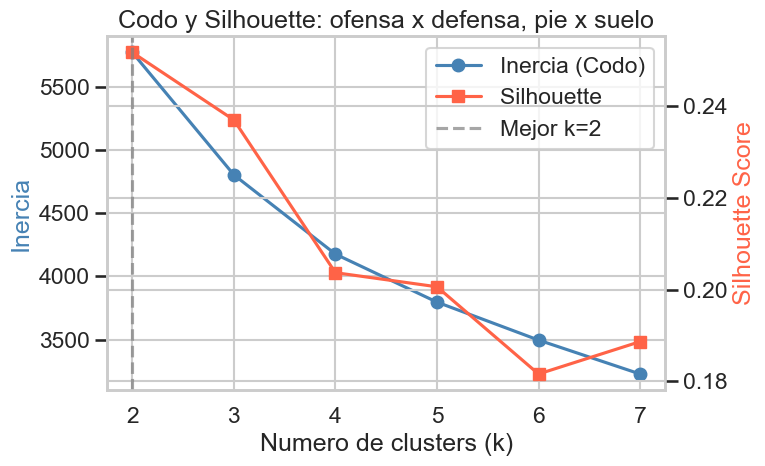


Mejor k segun Silhouette: 2  (score=0.2518)


In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# 1. Construir dataset de peleadores (una fila por peleador)
cols_4 = ['splm', 'str_def', 'td_avg', 'td_def']

red_4  = df_podado[['r_id', 'r_splm', 'r_str_def', 'r_td_avg', 'r_td_def']].copy()
red_4.columns  = ['fighter_id'] + cols_4
blue_4 = df_podado[['b_id', 'b_splm', 'b_str_def', 'b_td_avg', 'b_td_def']].copy()
blue_4.columns = ['fighter_id'] + cols_4

fighters_4 = pd.concat([red_4, blue_4], ignore_index=True).dropna()

# Deduplicar: promedio historico por peleador
fighters_4_dedup = fighters_4.groupby('fighter_id')[cols_4].mean().reset_index()

X4 = fighters_4_dedup[cols_4].values
scaler4 = StandardScaler()
X4_scaled = scaler4.fit_transform(X4)

print(f'Peleadores unicos para clustering: {len(fighters_4_dedup)}')

# 2. Validar k: codo + silhouette
inertias4, sil4 = [], []
K_range = range(2, 8)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X4_scaled)
    inertias4.append(km.inertia_)
    sil4.append(silhouette_score(X4_scaled, km.labels_))

fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(K_range, inertias4, marker='o', color='steelblue', label='Inercia (Codo)')
ax1.set_xlabel('Numero de clusters (k)')
ax1.set_ylabel('Inercia', color='steelblue')
ax2 = ax1.twinx()
ax2.plot(K_range, sil4, marker='s', color='tomato', label='Silhouette')
ax2.set_ylabel('Silhouette Score', color='tomato')
best_k = list(K_range)[sil4.index(max(sil4))]
ax2.axvline(best_k, linestyle='--', color='gray', alpha=0.7, label=f'Mejor k={best_k}')
plt.title('Codo y Silhouette: ofensa x defensa, pie x suelo')
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper right')
plt.tight_layout()
plt.savefig('../figures/codo_silhouette_4vars.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'\nMejor k segun Silhouette: {best_k}  (score={max(sil4):.4f})')


Centroides (escala original):


,splm,str_def,td_avg,td_def
Cluster,,,,
0,2.328,47.464,1.627,33.061
1,3.912,55.765,1.454,70.364


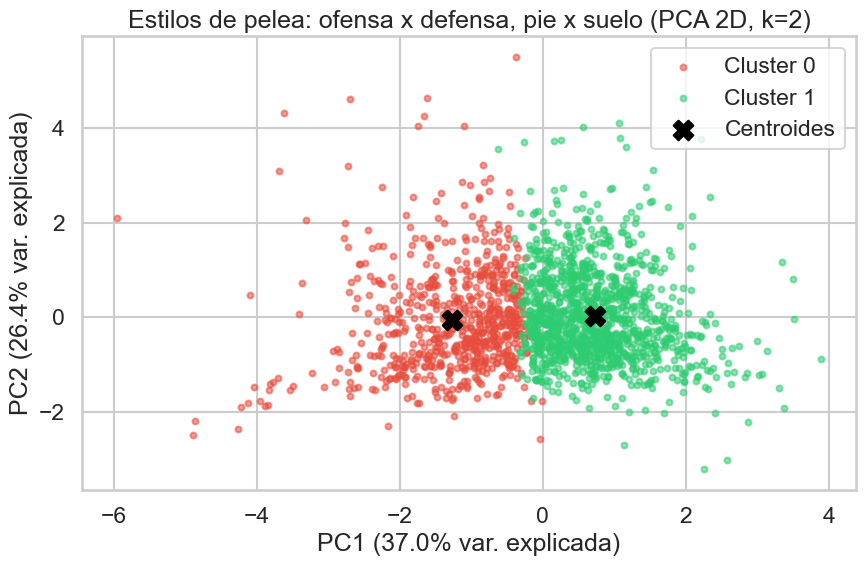


Varianza explicada PC1+PC2: 63.4%
Silhouette con k=2: 0.2518


In [59]:
# 3. Ajustar KMeans con el k optimo
km4 = KMeans(n_clusters=best_k, random_state=42, n_init=10)
fighters_4_dedup = fighters_4_dedup.copy()
fighters_4_dedup['cluster'] = km4.fit_predict(X4_scaled)

# Centroides en escala original
centroids4 = pd.DataFrame(
    scaler4.inverse_transform(km4.cluster_centers_),
    columns=cols_4
)
centroids4.index.name = 'Cluster'
print('Centroides (escala original):')
display(centroids4.round(3))

# 4. Visualizacion PCA 2D
pca = PCA(n_components=2, random_state=42)
X4_pca = pca.fit_transform(X4_scaled)

palette = ['#e74c3c', '#2ecc71', '#3498db', '#f39c12', '#9b59b6']
fig, ax = plt.subplots(figsize=(9, 6))
for c in range(best_k):
    mask = fighters_4_dedup['cluster'].values == c
    ax.scatter(X4_pca[mask, 0], X4_pca[mask, 1],
               s=18, alpha=0.55, color=palette[c], label=f'Cluster {c}')

centroids_pca = pca.transform(km4.cluster_centers_)
ax.scatter(centroids_pca[:, 0], centroids_pca[:, 1],
           s=200, marker='X', color='black', zorder=5, label='Centroides')

var_exp = pca.explained_variance_ratio_ * 100
ax.set_xlabel(f'PC1 ({var_exp[0]:.1f}% var. explicada)')
ax.set_ylabel(f'PC2 ({var_exp[1]:.1f}% var. explicada)')
ax.set_title(f'Estilos de pelea: ofensa x defensa, pie x suelo (PCA 2D, k={best_k})')
ax.legend()
plt.tight_layout()
plt.savefig('../figures/clustering_4vars_pca.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'\nVarianza explicada PC1+PC2: {sum(var_exp):.1f}%')
print(f'Silhouette con k={best_k}: {silhouette_score(X4_scaled, fighters_4_dedup["cluster"]):.4f}')


## Clustering de estilos: perfil de striking puro

Tres variables que describen el juego de pie sin mezclar grappling: volumen (`splm`), precision (`str_acc`) y defensa (`str_def`). Separa el striker de volumen, el francotirador preciso y el muro defensivo.

In [ ]:
# Funcion auxiliar para los agrupamientos reducidos (una fila por peleador)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from IPython.display import display

_palette = ['#e74c3c', '#2ecc71', '#3498db', '#f39c12', '#9b59b6']

def clustering_reducido(cols, cols_r, cols_b, fig_prefix, titulo):
    red = df_podado[['r_id'] + cols_r].copy();  red.columns = ['fighter_id'] + cols
    blue = df_podado[['b_id'] + cols_b].copy(); blue.columns = ['fighter_id'] + cols
    fighters = pd.concat([red, blue], ignore_index=True).dropna()
    dedup = fighters.groupby('fighter_id')[cols].mean().reset_index()
    X = dedup[cols].values
    scaler = StandardScaler(); Xs = scaler.fit_transform(X)
    print(f'Peleadores unicos: {len(dedup)}')

    inertias, sils = [], []
    K_range = range(2, 8)
    for k in K_range:
        km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(Xs)
        inertias.append(km.inertia_); sils.append(silhouette_score(Xs, km.labels_))
    best_k = list(K_range)[sils.index(max(sils))]

    fig, ax1 = plt.subplots(figsize=(8, 5))
    ax1.plot(K_range, inertias, marker='o', color='steelblue', label='Inercia (Codo)')
    ax1.set_xlabel('Numero de clusters (k)'); ax1.set_ylabel('Inercia', color='steelblue')
    ax2 = ax1.twinx()
    ax2.plot(K_range, sils, marker='s', color='tomato', label='Silhouette')
    ax2.set_ylabel('Silhouette Score', color='tomato')
    ax2.axvline(best_k, linestyle='--', color='gray', alpha=0.7, label=f'Mejor k={best_k}')
    plt.title(f'Codo y Silhouette: {titulo}')
    l1, lb1 = ax1.get_legend_handles_labels(); l2, lb2 = ax2.get_legend_handles_labels()
    ax1.legend(l1 + l2, lb1 + lb2, loc='upper right')
    plt.tight_layout()
    plt.savefig(f'../figures/codo_silhouette_{fig_prefix}.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Mejor k = {best_k}  (silhouette={max(sils):.4f})')

    km = KMeans(n_clusters=best_k, random_state=42, n_init=10)
    dedup = dedup.copy(); dedup['cluster'] = km.fit_predict(Xs)
    centroids = pd.DataFrame(scaler.inverse_transform(km.cluster_centers_), columns=cols)
    centroids['n'] = dedup['cluster'].value_counts().sort_index().values
    centroids.index.name = 'Cluster'
    print('Centroides (escala original):'); display(centroids.round(2))

    pca = PCA(n_components=2, random_state=42); Xp = pca.fit_transform(Xs)
    fig, ax = plt.subplots(figsize=(9, 6))
    for c in range(best_k):
        m = dedup['cluster'].values == c
        ax.scatter(Xp[m, 0], Xp[m, 1], s=18, alpha=0.55, color=_palette[c], label=f'Cluster {c}')
    cen = pca.transform(km.cluster_centers_)
    ax.scatter(cen[:, 0], cen[:, 1], s=200, marker='X', color='black', zorder=5, label='Centroides')
    ve = pca.explained_variance_ratio_ * 100
    ax.set_xlabel(f'PC1 ({ve[0]:.1f}% var. explicada)'); ax.set_ylabel(f'PC2 ({ve[1]:.1f}% var. explicada)')
    ax.set_title(f'{titulo} (PCA 2D, k={best_k})'); ax.legend()
    plt.tight_layout()
    plt.savefig(f'../figures/clustering_{fig_prefix}_pca.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Varianza PC1+PC2: {sum(ve):.1f}%')


In [ ]:
clustering_reducido(
    cols=['splm', 'str_acc', 'str_def'],
    cols_r=['r_splm', 'r_str_acc', 'r_str_def'],
    cols_b=['b_splm', 'b_str_acc', 'b_str_def'],
    fig_prefix='striking',
    titulo='Perfil de striking puro',
)

## Clustering de estilos: perfil de riesgo / intercambio de dano

Eje presion vs contragolpe: cuanto da (`splm`), cuanto recibe (`sapm`) y cuanto evita (`str_def`). Separa al pressure fighter del outfighter cauto.

In [ ]:
clustering_reducido(
    cols=['splm', 'sapm', 'str_def'],
    cols_r=['r_splm', 'r_sapm', 'r_str_def'],
    cols_b=['b_splm', 'b_sapm', 'b_str_def'],
    fig_prefix='riesgo',
    titulo='Perfil de riesgo / intercambio de dano',
)